# Northstar Retail — Profitability Investigation

**Working notebook · SQL → pandas → business insights**

Goal: understand why merchandise gross margin declined from 2024 to 2025, then validate the numbers against order status and returns.

**Two layers of analysis:**
- **Exploratory / preliminary:** all order items, before status and refund adjustments. Useful for diagnosing patterns, **not** recognized revenue.
- **Adjusted order-cohort scenario:** delivered orders only, refunds allocated to their **original order year**, and an **assumed 80% recovery** of returned inventory cost. This is a scenario estimate, not statutory revenue reporting.


## 01 · Setup and source data

Connect to local PostgreSQL and load the four source tables needed for the initial profitability analysis. The `returns` table is loaded later, when we need it.


In [553]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv(Path.cwd().parent / ".env")

db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("POSTGRES_USER"),
    password=os.getenv("POSTGRES_PASSWORD"),
    host="127.0.0.1",
    port=5433,
    database=os.getenv("POSTGRES_DB"),
)

engine = create_engine(db_url)

with engine.connect() as conn:
    result = conn.execute(text("SELECT current_database(), current_user"))
    print(result.fetchone())

('northstar_retail', 'northstar')


In [554]:
df_orders = pd.read_sql("SELECT * FROM orders", engine)
df_items = pd.read_sql("SELECT * FROM order_items", engine)
df_products = pd.read_sql("SELECT * FROM products", engine)
df_categories = pd.read_sql("SELECT * FROM categories", engine)

## 02 · Quick data checks

A first pass at shapes, types, missing values, duplicates and a few sample rows. These are intentionally separate checks — useful while exploring a new dataset.


In [555]:
df_orders.dtypes, '-------', df_items.dtypes, '-------', df_products.dtypes

(order_id                         int64
 customer_id                      int64
 order_ts           datetime64[us, UTC]
 order_status                       str
 subtotal                       float64
 discount_amount                float64
 tax_amount                     float64
 shipping_fee                   float64
 total_amount                   float64
 dtype: object,
 '-------',
 order_item_id        int64
 order_id             int64
 product_id           int64
 quantity             int64
 unit_price         float64
 unit_cost          float64
 line_subtotal      float64
 discount_amount    float64
 discount_code          str
 dtype: object,
 '-------',
 product_id        int64
 category_id       int64
 sku                 str
 product_name        str
 list_price      float64
 unit_cost       float64
 is_active          bool
 dtype: object)

In [556]:
df_orders.shape, '-------', df_items.shape, '-------', df_products.shape

((25000, 9), '-------', (65854, 9), '-------', (300, 7))

In [557]:
df_orders.isna().sum(), '-------', df_items.isna().sum(), '-------', df_products.isna().sum()

(order_id           0
 customer_id        0
 order_ts           0
 order_status       0
 subtotal           0
 discount_amount    0
 tax_amount         0
 shipping_fee       0
 total_amount       0
 dtype: int64,
 '-------',
 order_item_id          0
 order_id               0
 product_id             0
 quantity               0
 unit_price             0
 unit_cost              0
 line_subtotal          0
 discount_amount        0
 discount_code      43646
 dtype: int64,
 '-------',
 product_id      0
 category_id     0
 sku             0
 product_name    0
 list_price      0
 unit_cost       0
 is_active       0
 dtype: int64)

In [558]:
df_orders.duplicated().sum(), df_items.duplicated().sum(), df_products.duplicated().sum()

(np.int64(0), np.int64(0), np.int64(0))

In [559]:
df_orders.head(5), '-------', df_items.head(5), '-------', df_products.head(5)

(   order_id  customer_id                  order_ts order_status  subtotal  \
 0         1         2499 2024-05-19 14:54:33+00:00      shipped    130.33   
 1         2          592 2025-07-12 23:01:45+00:00         paid     39.52   
 2         3         2516 2024-11-08 04:17:56+00:00         paid    378.80   
 3         4         3141 2024-12-24 12:51:44+00:00    delivered    300.24   
 4         5         3927 2024-06-24 11:46:54+00:00      shipped    221.02   
 
    discount_amount  tax_amount  shipping_fee  total_amount  
 0             0.00       10.43          0.00        140.76  
 1             0.00        3.16          6.95         49.63  
 2            24.83       28.32          0.00        382.29  
 3             5.37       23.59          0.00        318.46  
 4             6.58       17.16          0.00        231.60  ,
 '-------',
    order_item_id  order_id  product_id  quantity  unit_price  unit_cost  \
 0              1         1          74         2       37.49      25

In [560]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   order_id         25000 non-null  int64              
 1   customer_id      25000 non-null  int64              
 2   order_ts         25000 non-null  datetime64[us, UTC]
 3   order_status     25000 non-null  str                
 4   subtotal         25000 non-null  float64            
 5   discount_amount  25000 non-null  float64            
 6   tax_amount       25000 non-null  float64            
 7   shipping_fee     25000 non-null  float64            
 8   total_amount     25000 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(5), int64(2), str(1)
memory usage: 1.7 MB


In [561]:
df_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 65854 entries, 0 to 65853
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_item_id    65854 non-null  int64  
 1   order_id         65854 non-null  int64  
 2   product_id       65854 non-null  int64  
 3   quantity         65854 non-null  int64  
 4   unit_price       65854 non-null  float64
 5   unit_cost        65854 non-null  float64
 6   line_subtotal    65854 non-null  float64
 7   discount_amount  65854 non-null  float64
 8   discount_code    22208 non-null  str    
dtypes: float64(4), int64(4), str(1)
memory usage: 4.5 MB


In [562]:
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    300 non-null    int64  
 1   category_id   300 non-null    int64  
 2   sku           300 non-null    str    
 3   product_name  300 non-null    str    
 4   list_price    300 non-null    float64
 5   unit_cost     300 non-null    float64
 6   is_active     300 non-null    bool   
dtypes: bool(1), float64(2), int64(2), str(2)
memory usage: 14.5 KB


### Discount quality check

Before calculating sales after discounts, check for unusual combinations of discount codes and actual discount amounts. Having a code with a zero discount is worth flagging, but not automatically a data error.


In [563]:
mask = (
    (df_items.discount_amount > 0) &
    (df_items.discount_code.isnull())
)

mask.sum()

np.int64(0)

In [564]:
mask = (
    (df_items.discount_amount == 0) &
    (df_items.discount_code.notnull())
)

mask.sum()

np.int64(38)

In [565]:
suspicious_items = df_items.loc[
    (df_items["discount_amount"] == 0)
    & (df_items["discount_code"].notna())
]

suspicious_items.head()

,order_item_id,order_id,product_id,quantity,unit_price,unit_cost,line_subtotal,discount_amount,discount_code
1823,1824,701,144,1,13.59,9.59,13.59,0.0,MYSTERY_DEAL
4875,4876,1856,236,1,52.55,37.18,52.55,0.0,MYSTERY_DEAL
6389,6390,2412,129,2,34.41,24.78,68.82,0.0,MYSTERY_DEAL
6831,6832,2580,29,1,32.03,18.11,32.03,0.0,MYSTERY_DEAL
6865,6866,2594,1,1,52.44,38.02,52.44,0.0,MYSTERY_DEAL


## 03 · Build the sales dataset

**Grain: one row per order item.** Merge order, product and category attributes onto each item. Names such as `order_discount`, `item_discount` and `item_unit_cost` help keep the source of each measure explicit. **Do not sum order-level totals from this merged table** — they repeat once per item.


In [566]:
orders = df_orders.rename(
    columns={"discount_amount": "order_discount"}
)

items = df_items.rename(
    columns={
        "discount_amount": "item_discount",
        "unit_cost": "item_unit_cost"
    }
)

products = df_products.rename(
    columns={"unit_cost": "catalog_unit_cost"}
)

df_sales = (
    orders
    .merge(
        items,
        on="order_id",
        how="inner",
        validate="one_to_many"
    )
    .merge(
        products,
        on="product_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        df_categories,
        on="category_id",
        how="inner",
        validate="many_to_one"
    )
)


In [567]:
df_sales.head(5)

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,item_discount,discount_code,category_id,sku,product_name,list_price,catalog_unit_cost,is_active,category_name,description
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,1,...,0.00,NaN,4,NS-04-0074,Summit Backpack 074,38.42,27.48,True,Beauty,Northstar beauty assortment
1,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,2,...,0.00,NaN,4,NS-04-0044,Summit Backpack 044,37.24,25.78,True,Beauty,Northstar beauty assortment
2,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,3,...,0.00,NaN,7,NS-07-0117,Heritage Bottle 117,19.08,14.01,False,Toys,Northstar toys assortment
3,2,592,2025-07-12 23:01:45+00:00,paid,39.52,0.00,3.16,6.95,49.63,4,...,0.00,NaN,7,NS-07-0177,Heritage Bottle 177,40.02,30.43,True,Toys,Northstar toys assortment
4,3,2516,2024-11-08 04:17:56+00:00,paid,378.80,24.83,28.32,0.00,382.29,5,...,22.94,CLEARANCE,7,NS-07-0097,Heritage Bottle 097,77.47,57.65,True,Toys,Northstar toys assortment


In [568]:
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 65854 entries, 0 to 65853
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   order_id           65854 non-null  int64              
 1   customer_id        65854 non-null  int64              
 2   order_ts           65854 non-null  datetime64[us, UTC]
 3   order_status       65854 non-null  str                
 4   subtotal           65854 non-null  float64            
 5   order_discount     65854 non-null  float64            
 6   tax_amount         65854 non-null  float64            
 7   shipping_fee       65854 non-null  float64            
 8   total_amount       65854 non-null  float64            
 9   order_item_id      65854 non-null  int64              
 10  product_id         65854 non-null  int64              
 11  quantity           65854 non-null  int64              
 12  unit_price         65854 non-null  float64            
 1

In [569]:
df_sales.isnull().sum()

order_id                 0
customer_id              0
order_ts                 0
order_status             0
subtotal                 0
order_discount           0
tax_amount               0
shipping_fee             0
total_amount             0
order_item_id            0
product_id               0
quantity                 0
unit_price               0
item_unit_cost           0
line_subtotal            0
item_discount            0
discount_code        43646
category_id              0
sku                      0
product_name             0
list_price               0
catalog_unit_cost        0
is_active                0
category_name            0
description              0
dtype: int64

In [570]:
df_sales["net_line_value"] = df_sales.line_subtotal - df_sales.item_discount
df_sales["line_cogs"] = df_sales.item_unit_cost * df_sales.quantity
df_sales["line_gross_profit"] = df_sales.net_line_value - df_sales.line_cogs
df_sales["profit_margin_pct"] = df_sales["line_gross_profit"] / df_sales["net_line_value"] * 100

In [571]:
df_sales.head()

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,product_name,list_price,catalog_unit_cost,is_active,category_name,description,net_line_value,line_cogs,line_gross_profit,profit_margin_pct
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,1,...,Summit Backpack 074,38.42,27.48,True,Beauty,Northstar beauty assortment,74.98,50.52,24.46,32.622033
1,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,2,...,Summit Backpack 044,37.24,25.78,True,Beauty,Northstar beauty assortment,36.57,23.84,12.73,34.809954
2,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,3,...,Heritage Bottle 117,19.08,14.01,False,Toys,Northstar toys assortment,18.78,12.97,5.81,30.937167
3,2,592,2025-07-12 23:01:45+00:00,paid,39.52,0.00,3.16,6.95,49.63,4,...,Heritage Bottle 177,40.02,30.43,True,Toys,Northstar toys assortment,39.52,30.34,9.18,23.228745
4,3,2516,2024-11-08 04:17:56+00:00,paid,378.80,24.83,28.32,0.00,382.29,5,...,Heritage Bottle 097,77.47,57.65,True,Toys,Northstar toys assortment,206.44,158.55,47.89,23.198024


The three core line-level measures are:

- `net_line_value = line_subtotal - item_discount` (merchandise value after discounts)
- `line_cogs = quantity × item_unit_cost`
- `line_gross_profit = net_line_value - line_cogs`

We will aggregate **amounts first** and only then calculate gross margin percentages.


## 04 · Initial profitability by category and month

**Exploratory only — all order statuses included.** Start by locating the largest sources of gross profit, then inspect how gross margin evolves over time.


In [572]:
df_category = (
    df_sales
    .groupby("category_name")
    .agg(
        net_sales = ("net_line_value", "sum"),
        cogs = ("line_cogs", "sum"),
        gross_profit = ("line_gross_profit", "sum")
    )
    .reset_index()
)

df_category

,category_name,net_sales,cogs,gross_profit
0,Apparel,272320.18,187579.76,84740.42
1,Beauty,310166.07,212079.62,98086.45
2,Books,294080.86,203033.22,91047.64
3,Electronics,297886.49,203392.06,94494.43
4,Grocery,347832.25,238005.51,109826.74
5,Home & Kitchen,343259.82,232484.59,110775.23
6,Office,301974.37,203693.65,98280.72
7,Pet Supplies,317821.05,219516.29,98304.76
8,Sports & Outdoors,298715.30,207749.82,90965.48
9,Toys,304718.55,213944.21,90774.34


In [573]:
import numpy as np

df_category["profit_margin_pct"] = np.where(
    df_category["net_sales"] != 0,
    df_category["gross_profit"] / df_category["net_sales"] * 100,
    np.nan
)

df_category["profit_margin_pct"] = (
    df_category["profit_margin_pct"].round(2)
)

In [574]:
print(df_sales["net_line_value"].sum())
print(df_category["net_sales"].sum())

3088774.94
3088774.9399999995


In [575]:
df_category = df_category.sort_values("gross_profit", ascending=False).reset_index(drop=True)
df_category

,category_name,net_sales,cogs,gross_profit,profit_margin_pct
0,Home & Kitchen,343259.82,232484.59,110775.23,32.27
1,Grocery,347832.25,238005.51,109826.74,31.57
2,Pet Supplies,317821.05,219516.29,98304.76,30.93
3,Office,301974.37,203693.65,98280.72,32.55
4,Beauty,310166.07,212079.62,98086.45,31.62
5,Electronics,297886.49,203392.06,94494.43,31.72
6,Books,294080.86,203033.22,91047.64,30.96
7,Sports & Outdoors,298715.30,207749.82,90965.48,30.45
8,Toys,304718.55,213944.21,90774.34,29.79
9,Apparel,272320.18,187579.76,84740.42,31.12


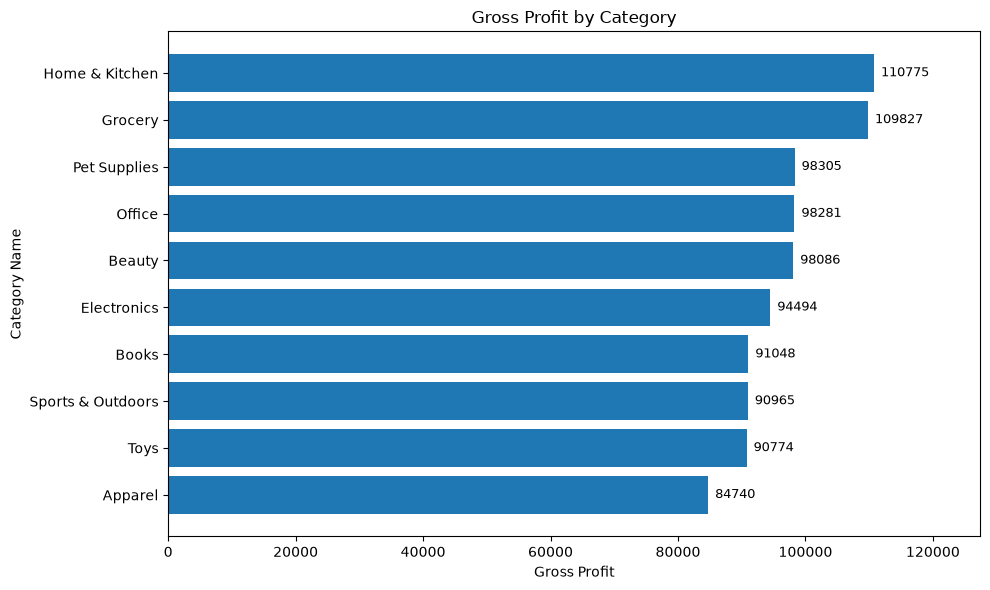

In [576]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.set_xlabel("Gross Profit")
ax.set_ylabel("Category Name")
ax.set_title("Gross Profit by Category")

ax.invert_yaxis()

bars = ax.barh(
    df_category["category_name"],
    df_category["gross_profit"]
)
ax.bar_label(
    bars,
    fmt="%.0f",
    padding=5,
    fontsize=9
)
ax.set_xlim(0, df_category["gross_profit"].max() * 1.15)

plt.tight_layout()
plt.show()

In [577]:
df_sales["month"] = (
    df_sales["order_ts"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
    .dt.to_period("M")
)

In [578]:
df_month_margin = (
    df_sales.groupby("month")
    .agg(
        net_sales = ("net_line_value", "sum"),
        gross_profit = ("line_gross_profit", "sum"),
        cogs = ("line_cogs", "sum")
    ).reset_index()
)

In [579]:
df_month_margin["gross_margin_pct"] = np.where(
    df_month_margin["net_sales"] != 0,
    df_month_margin["gross_profit"] / df_month_margin["net_sales"] * 100,
    np.nan
)

In [580]:
df_month_margin

,month,net_sales,gross_profit,cogs,gross_margin_pct
0,2024-01,100851.38,33805.35,67046.03,33.519968
1,2024-02,89129.31,29508.74,59620.57,33.107785
2,2024-03,100372.32,33347.58,67024.74,33.223881
3,2024-04,102394.98,34230.95,68164.03,33.430301
4,2024-05,116173.47,38486.01,77687.46,33.128054
5,2024-06,108777.82,36320.51,72457.31,33.389629
6,2024-07,123975.94,41179.74,82796.20,33.215913
7,2024-08,121793.29,40707.65,81085.64,33.423557
8,2024-09,123074.18,41501.35,81572.83,33.720598
9,2024-10,135444.05,45204.09,90239.96,33.374733


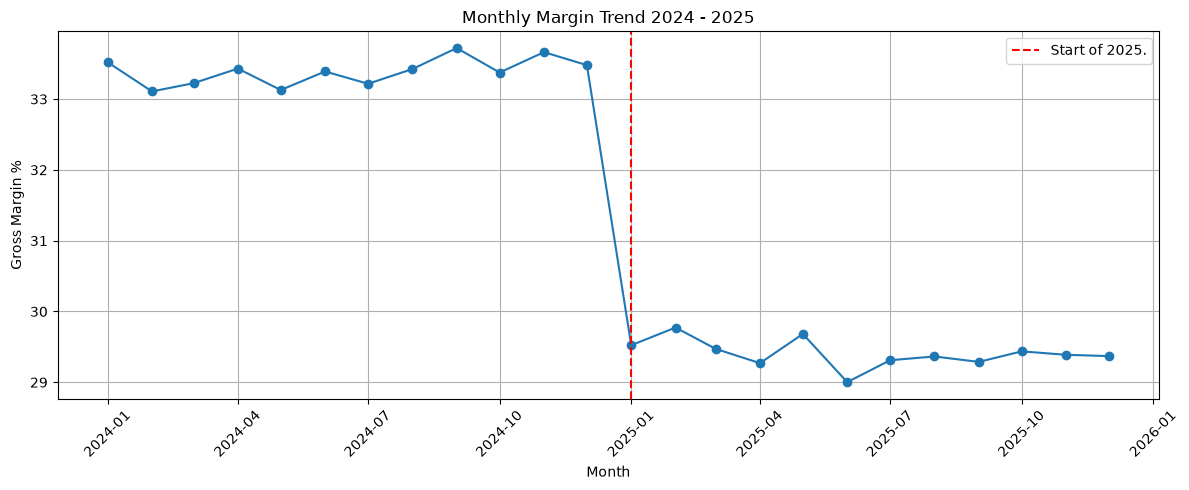

In [581]:
fig2, ax2 = plt.subplots(figsize=(12, 5))
x = df_month_margin["month"].dt.to_timestamp()
y = df_month_margin["gross_margin_pct"]
ax2.plot(x, y, marker='o')
ax2.set_xlabel("Month")
ax2.set_ylabel("Gross Margin %")
ax2.set_title("Monthly Margin Trend 2024 - 2025")
ax2.grid(True)

ax2.axvline(x=pd.Timestamp("2025-01-01"), color='red', linestyle='--', label='Start of 2025.')
ax2.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [582]:
df_sales["year"] = (
    df_sales["order_ts"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
    .dt.year
)

df_sales.columns

Index(['order_id', 'customer_id', 'order_ts', 'order_status', 'subtotal',
       'order_discount', 'tax_amount', 'shipping_fee', 'total_amount',
       'order_item_id', 'product_id', 'quantity', 'unit_price',
       'item_unit_cost', 'line_subtotal', 'item_discount', 'discount_code',
       'category_id', 'sku', 'product_name', 'list_price', 'catalog_unit_cost',
       'is_active', 'category_name', 'description', 'net_line_value',
       'line_cogs', 'line_gross_profit', 'profit_margin_pct', 'month', 'year'],
      dtype='str')

**Observation:** the original monthly view shows a step down in margin around the beginning of 2025. This is an investigative lead, not an explanation of cause. The 2024/2025 metrics below are still based on **all** order statuses.


## 05 · Year-over-year metrics and category drivers

Build the yearly baseline, then investigate category-level average price, average cost and shifts in category sales share.


In [583]:
df_yearly = df_sales.groupby("year").agg(
    quantity=("quantity", "sum"),
    line_subtotal=("line_subtotal", "sum"),
    item_discount=("item_discount", "sum"),
    line_cogs=("line_cogs", "sum"),
    line_gross_profit=("line_gross_profit", "sum")
)

df_yearly["avg_unit_price"] = (df_yearly["line_subtotal"] - df_yearly["item_discount"]) / df_yearly["quantity"]
df_yearly["avg_unit_cost"] = df_yearly["line_cogs"] / df_yearly["quantity"]
df_yearly["avg_unit_gross_profit"] = df_yearly["line_gross_profit"] / df_yearly["quantity"]
df_yearly["avg_unit_discount"] = df_yearly["item_discount"] / df_yearly["quantity"]
df_yearly["avg_discount_rate_pct"] = (df_yearly["item_discount"] / df_yearly["line_subtotal"] * 100)
df_yearly["gross_margin_pct"] = (df_yearly["line_gross_profit"] / (df_yearly["line_subtotal"] - df_yearly["item_discount"]) * 100)

In [584]:
df_yearly

,quantity,line_subtotal,item_discount,line_cogs,line_gross_profit,avg_unit_price,avg_unit_cost,avg_unit_gross_profit,avg_unit_discount,avg_discount_rate_pct,gross_margin_pct
year,,,,,,,,,,,
2024,38578,1536387.70,58991.62,983818.97,493577.11,38.296337,25.502073,12.794264,1.529152,3.839631,33.408584
2025,40696,1694765.47,83386.61,1137659.76,473719.10,39.595510,27.955076,11.640434,2.049012,4.920245,29.398369


In [585]:
df_category_yearly = df_sales.groupby(["year", "category_name"]).agg(
    units_sold=("quantity", "sum"),
    net_sales=("net_line_value", "sum"),
    line_cogs=("line_cogs", "sum"),
    line_gross_profit=("line_gross_profit", "sum")
)
df_category_yearly["net_asp"] = df_category_yearly["net_sales"] / df_category_yearly["units_sold"]
df_category_yearly["avg_unit_cost"] = df_category_yearly["line_cogs"] / df_category_yearly["units_sold"]
df_category_yearly["gross_margin_pct"] = (df_category_yearly["line_gross_profit"] / df_category_yearly["net_sales"].replace(0, np.nan) * 100)
df_category_yearly

units_sold  net_sales  line_cogs  line_gross_profit  \
year category_name                                                            
2024 Apparel                  3849  131047.91   87264.25           43783.66   
     Beauty                   3817  148257.46   98104.84           50152.62   
     Books                    3796  140135.59   93666.84           46468.75   
     Electronics              3988  149359.69   99056.37           50303.32   
     Grocery                  3889  163110.98  108806.26           54304.72   
     Home & Kitchen           3876  159777.05  104795.05           54982.00   
     Office                   3771  144397.75   94307.06           50090.69   
     Pet Supplies             3906  152254.55  102243.17           50011.38   
     Sports & Outdoors        3890  141286.79   94954.14           46332.65   
     Toys                     3796  147768.31  100620.99           47147.32   
2025 Apparel                  4068  141272.27  100315.51           40956.76   
     Beauty                   3964  161908.61  113974.78           47933.83   
     Books                    3978  153945.27  109366.38           44578.89   
     Electronics              3930  148526.80  104335.69           44191.11   
     Grocery                  4197  184721.27  129199.25           55522.02   
     Home & Kitchen           4281  183482.77  127689.54           55793.23   
     Office                   3998  157576.62  109386.59           48190.03   
     Pet Supplies             4107  165566.50  117273.12           48293.38   
     Sports & Outdoors        4182  157428.51  112795.68           44632.83   
     Toys                     3991  156950.24  113323.22           43627.02   

                          net_asp  avg_unit_cost  gross_margin_pct  
year category_name                                                  
2024 Apparel            34.047262      22.671928         33.410422  
     Beauty             38.841357      25.702080         33.828058  
     Books              36.916646      24.675142         33.159849  
     Electronics        37.452279      24.838608         33.679315  
     Grocery            41.941625      27.977953         33.293111  
     Home & Kitchen     41.222149      27.036907         34.411701  
     Office             38.291634      25.008502         34.689384  
     Pet Supplies       38.979659      26.175927         32.847215  
     Sports & Outdoors  36.320512      24.409805         32.793335  
     Toys               38.927374      26.507110         31.906246  
2025 Apparel            34.727697      24.659663         28.991365  
     Beauty             40.844755      28.752467         29.605485  
     Books              38.699163      27.492805         28.957622  
     Electronics        37.793079      26.548522         29.752954  
     Grocery            44.012692      30.783715         30.057188  
     Home & Kitchen     42.859792      29.827036         30.407885  
     Office             39.413862      27.360328         30.581967  
     Pet Supplies       40.313246      28.554449         29.168570  
     Sports & Outdoors  37.644311      26.971707         28.351173  
     Toys               39.326044      28.394693         27.796721

### Price vs cost — category comparisons

`net_asp = net_sales / units_sold` and `avg_unit_cost = cogs / units_sold` are quantity-weighted averages. A difference in their **growth rates** highlights margin pressure, but does not isolate purchase-price changes for the *same SKU*. Product mix may also have changed.


In [586]:
df_cost_comparison = df_category_yearly.reset_index().pivot(
        index="category_name",
        columns="year",
        values="avg_unit_cost"
    )

df_cost_comparison["cost_growth_pct"] = ((df_cost_comparison[2025] - df_cost_comparison[2024]) / df_cost_comparison[2024] * 100).round(2)
df_cost_comparison = df_cost_comparison.sort_values("cost_growth_pct", ascending=False)

df_cost_comparison = df_cost_comparison.rename(
    columns={
        2024: "cost_2024",
        2025: "cost_2025"
    }
)

df_cost_comparison

year,cost_2024,cost_2025,cost_growth_pct
category_name,,,
Beauty,25.702080,28.752467,11.87
Books,24.675142,27.492805,11.42
Sports & Outdoors,24.409805,26.971707,10.50
Home & Kitchen,27.036907,29.827036,10.32
Grocery,27.977953,30.783715,10.03
Office,25.008502,27.360328,9.40
Pet Supplies,26.175927,28.554449,9.09
Apparel,22.671928,24.659663,8.77
Toys,26.507110,28.394693,7.12


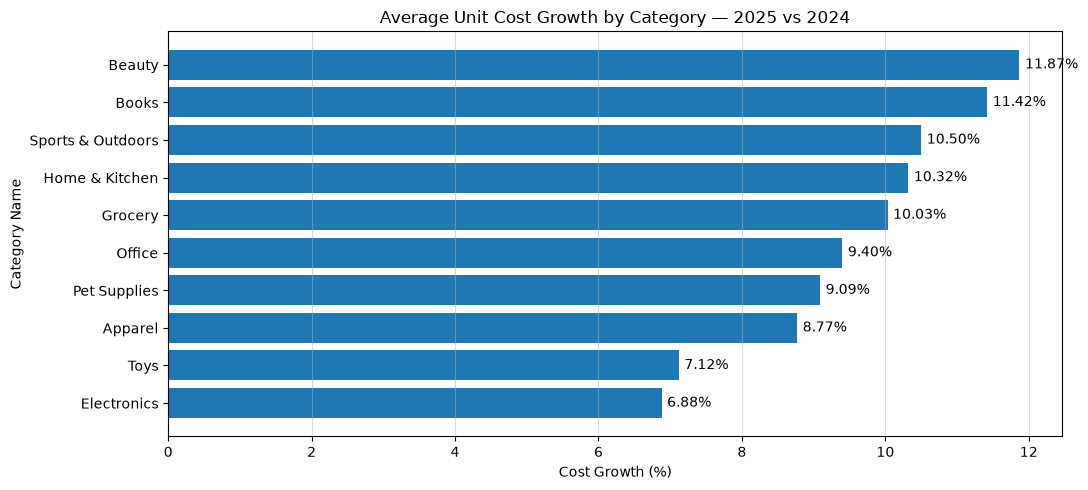

In [587]:
fig3, ax3 = plt.subplots(figsize=(11, 5))
x = df_cost_comparison.index
y = df_cost_comparison["cost_growth_pct"]
    
ax3.set_xlabel("Cost Growth (%)")
ax3.set_ylabel("Category Name")
ax3.set_title("Average Unit Cost Growth by Category — 2025 vs 2024")
ax3.grid(axis="x", alpha=0.5)
    
ax3.invert_yaxis()

bars = ax3.barh(x, y)

ax3.bar_label(
    bars,
    labels=[f"{v:.2f}%" for v in y],
    padding=4,
    fontsize=10
)

plt.tight_layout()
plt.show()


In [588]:
df_category_yearly

units_sold  net_sales  line_cogs  line_gross_profit  \
year category_name                                                            
2024 Apparel                  3849  131047.91   87264.25           43783.66   
     Beauty                   3817  148257.46   98104.84           50152.62   
     Books                    3796  140135.59   93666.84           46468.75   
     Electronics              3988  149359.69   99056.37           50303.32   
     Grocery                  3889  163110.98  108806.26           54304.72   
     Home & Kitchen           3876  159777.05  104795.05           54982.00   
     Office                   3771  144397.75   94307.06           50090.69   
     Pet Supplies             3906  152254.55  102243.17           50011.38   
     Sports & Outdoors        3890  141286.79   94954.14           46332.65   
     Toys                     3796  147768.31  100620.99           47147.32   
2025 Apparel                  4068  141272.27  100315.51           40956.76   
     Beauty                   3964  161908.61  113974.78           47933.83   
     Books                    3978  153945.27  109366.38           44578.89   
     Electronics              3930  148526.80  104335.69           44191.11   
     Grocery                  4197  184721.27  129199.25           55522.02   
     Home & Kitchen           4281  183482.77  127689.54           55793.23   
     Office                   3998  157576.62  109386.59           48190.03   
     Pet Supplies             4107  165566.50  117273.12           48293.38   
     Sports & Outdoors        4182  157428.51  112795.68           44632.83   
     Toys                     3991  156950.24  113323.22           43627.02   

                          net_asp  avg_unit_cost  gross_margin_pct  
year category_name                                                  
2024 Apparel            34.047262      22.671928         33.410422  
     Beauty             38.841357      25.702080         33.828058  
     Books              36.916646      24.675142         33.159849  
     Electronics        37.452279      24.838608         33.679315  
     Grocery            41.941625      27.977953         33.293111  
     Home & Kitchen     41.222149      27.036907         34.411701  
     Office             38.291634      25.008502         34.689384  
     Pet Supplies       38.979659      26.175927         32.847215  
     Sports & Outdoors  36.320512      24.409805         32.793335  
     Toys               38.927374      26.507110         31.906246  
2025 Apparel            34.727697      24.659663         28.991365  
     Beauty             40.844755      28.752467         29.605485  
     Books              38.699163      27.492805         28.957622  
     Electronics        37.793079      26.548522         29.752954  
     Grocery            44.012692      30.783715         30.057188  
     Home & Kitchen     42.859792      29.827036         30.407885  
     Office             39.413862      27.360328         30.581967  
     Pet Supplies       40.313246      28.554449         29.168570  
     Sports & Outdoors  37.644311      26.971707         28.351173  
     Toys               39.326044      28.394693         27.796721

In [589]:
df_cost_comparison

year,cost_2024,cost_2025,cost_growth_pct
category_name,,,
Beauty,25.702080,28.752467,11.87
Books,24.675142,27.492805,11.42
Sports & Outdoors,24.409805,26.971707,10.50
Home & Kitchen,27.036907,29.827036,10.32
Grocery,27.977953,30.783715,10.03
Office,25.008502,27.360328,9.40
Pet Supplies,26.175927,28.554449,9.09
Apparel,22.671928,24.659663,8.77
Toys,26.507110,28.394693,7.12


In [590]:
df_sales_comparison = df_category_yearly.reset_index().pivot(
    index="category_name",
    columns="year",
    values="net_asp"
)

df_sales_comparison["asp_growth_pct"] = ((df_sales_comparison[2025] - df_sales_comparison[2024]) / df_sales_comparison[2024] * 100).round(2)

In [591]:
df_sales_comparison

year,2024,2025,asp_growth_pct
category_name,,,
Apparel,34.047262,34.727697,2.00
Beauty,38.841357,40.844755,5.16
Books,36.916646,38.699163,4.83
Electronics,37.452279,37.793079,0.91
Grocery,41.941625,44.012692,4.94
Home & Kitchen,41.222149,42.859792,3.97
Office,38.291634,39.413862,2.93
Pet Supplies,38.979659,40.313246,3.42
Sports & Outdoors,36.320512,37.644311,3.64


In [592]:
df_price_cost_comparison = pd.concat(
    [df_cost_comparison["cost_growth_pct"], df_sales_comparison["asp_growth_pct"]],
    axis=1
)
df_price_cost_comparison.columns = ["cost_growth_pct", "asp_growth_pct"]
df_price_cost_comparison["growth_gap_pp"] = (df_price_cost_comparison["asp_growth_pct"] - df_price_cost_comparison["cost_growth_pct"]).round(2)
df_price_cost_comparison = df_price_cost_comparison.sort_values(by="growth_gap_pp", ascending=False)
df_price_cost_comparison

,cost_growth_pct,asp_growth_pct,growth_gap_pp
category_name,,,
Grocery,10.03,4.94,-5.09
Pet Supplies,9.09,3.42,-5.67
Electronics,6.88,0.91,-5.97
Toys,7.12,1.02,-6.10
Home & Kitchen,10.32,3.97,-6.35
Office,9.40,2.93,-6.47
Books,11.42,4.83,-6.59
Beauty,11.87,5.16,-6.71
Apparel,8.77,2.00,-6.77


### Sales mix and margin bridge

**Sales Share** is a category's share of annual merchandise sales. **Mix Effect** asks how much the company's margin would have changed if category margins had stayed at their 2024 levels but category shares shifted to 2025.

For the bridge below we keep **unrounded** shares and margins. We only round displayed output.


In [593]:
df_sales_mix = df_category_yearly.reset_index().pivot(
        index="category_name",
        columns="year",
        values="net_sales"
    )

df_sales_mix["share_2024_pct"] = (
    df_sales_mix[2024] / df_sales_mix[2024].sum() * 100
)

df_sales_mix["share_2025_pct"] = (
    df_sales_mix[2025] / df_sales_mix[2025].sum() * 100
)

df_sales_mix["share_change_pp"] = (
    df_sales_mix["share_2025_pct"] - df_sales_mix["share_2024_pct"]
)

df_sales_mix


year,2024,2025,share_2024_pct,share_2025_pct,share_change_pp
category_name,,,,,
Apparel,131047.91,141272.27,8.870195,8.767167,-0.103028
Beauty,148257.46,161908.61,10.035052,10.047830,0.012778
Books,140135.59,153945.27,9.485309,9.553636,0.068326
Electronics,149359.69,148526.80,10.109658,9.217373,-0.892285
Grocery,163110.98,184721.27,11.040437,11.463553,0.423116
Home & Kitchen,159777.05,183482.77,10.814774,11.386693,0.571919
Office,144397.75,157576.62,9.773801,9.778993,0.005192
Pet Supplies,152254.55,165566.50,10.305601,10.274834,-0.030768
Sports & Outdoors,141286.79,157428.51,9.563230,9.769801,0.206571


In [594]:
print(df_sales_mix["share_2024_pct"].sum())
print(df_sales_mix["share_2025_pct"].sum())

100.0
100.00000000000001


In [595]:
df_sales_mix

year,2024,2025,share_2024_pct,share_2025_pct,share_change_pp
category_name,,,,,
Apparel,131047.91,141272.27,8.870195,8.767167,-0.103028
Beauty,148257.46,161908.61,10.035052,10.047830,0.012778
Books,140135.59,153945.27,9.485309,9.553636,0.068326
Electronics,149359.69,148526.80,10.109658,9.217373,-0.892285
Grocery,163110.98,184721.27,11.040437,11.463553,0.423116
Home & Kitchen,159777.05,183482.77,10.814774,11.386693,0.571919
Office,144397.75,157576.62,9.773801,9.778993,0.005192
Pet Supplies,152254.55,165566.50,10.305601,10.274834,-0.030768
Sports & Outdoors,141286.79,157428.51,9.563230,9.769801,0.206571


In [596]:
df_sales_mix_effect = df_sales_mix.copy()
df_sales_mix_effect["gross_margin_2024_pct"] = df_category_yearly["gross_margin_pct"][2024]
df_sales_mix_effect["gross_margin_2025_pct"] = df_category_yearly["gross_margin_pct"][2025]

In [597]:
df_sales_mix_effect["mix_effect_pp"] = (
    df_sales_mix_effect["share_change_pp"] / 100 * df_sales_mix_effect["gross_margin_2024_pct"]
)

In [598]:
df_sales_mix_effect

year,2024,2025,share_2024_pct,share_2025_pct,share_change_pp,gross_margin_2024_pct,gross_margin_2025_pct,mix_effect_pp
category_name,,,,,,,,
Apparel,131047.91,141272.27,8.870195,8.767167,-0.103028,33.410422,28.991365,-0.034422
Beauty,148257.46,161908.61,10.035052,10.047830,0.012778,33.828058,29.605485,0.004323
Books,140135.59,153945.27,9.485309,9.553636,0.068326,33.159849,28.957622,0.022657
Electronics,149359.69,148526.80,10.109658,9.217373,-0.892285,33.679315,29.752954,-0.300515
Grocery,163110.98,184721.27,11.040437,11.463553,0.423116,33.293111,30.057188,0.140869
Home & Kitchen,159777.05,183482.77,10.814774,11.386693,0.571919,34.411701,30.407885,0.196807
Office,144397.75,157576.62,9.773801,9.778993,0.005192,34.689384,30.581967,0.001801
Pet Supplies,152254.55,165566.50,10.305601,10.274834,-0.030768,32.847215,29.168570,-0.010106
Sports & Outdoors,141286.79,157428.51,9.563230,9.769801,0.206571,32.793335,28.351173,0.067741


In [599]:
total_mix_effect_pp = df_sales_mix_effect["mix_effect_pp"].sum()

print(f"Total Sales Mix Effect: {total_mix_effect_pp:.4f} pp")
print(f"Average Gross Margin Change: {(df_yearly.gross_margin_pct[2025] - df_yearly.gross_margin_pct[2024]).round(4):.4f} %")

Total Sales Mix Effect: 0.0056 pp
Average Gross Margin Change: -4.0102 %


In [600]:
df_sales_mix_effect["within_category_effect_pp"] = (
    df_sales_mix_effect["share_2025_pct"] / 100
    * (
        df_sales_mix_effect["gross_margin_2025_pct"]
        - df_sales_mix_effect["gross_margin_2024_pct"]
    )
)
df_sales_mix_effect

year,2024,2025,share_2024_pct,share_2025_pct,share_change_pp,gross_margin_2024_pct,gross_margin_2025_pct,mix_effect_pp,within_category_effect_pp
category_name,,,,,,,,,
Apparel,131047.91,141272.27,8.870195,8.767167,-0.103028,33.410422,28.991365,-0.034422,-0.387426
Beauty,148257.46,161908.61,10.035052,10.047830,0.012778,33.828058,29.605485,0.004323,-0.424277
Books,140135.59,153945.27,9.485309,9.553636,0.068326,33.159849,28.957622,0.022657,-0.401465
Electronics,149359.69,148526.80,10.109658,9.217373,-0.892285,33.679315,29.752954,-0.300515,-0.361907
Grocery,163110.98,184721.27,11.040437,11.463553,0.423116,33.293111,30.057188,0.140869,-0.370952
Home & Kitchen,159777.05,183482.77,10.814774,11.386693,0.571919,34.411701,30.407885,0.196807,-0.455902
Office,144397.75,157576.62,9.773801,9.778993,0.005192,34.689384,30.581967,0.001801,-0.401664
Pet Supplies,152254.55,165566.50,10.305601,10.274834,-0.030768,32.847215,29.168570,-0.010106,-0.377975
Sports & Outdoors,141286.79,157428.51,9.563230,9.769801,0.206571,32.793335,28.351173,0.067741,-0.433990


In [601]:
mix_effect = df_sales_mix_effect["mix_effect_pp"].sum()

within_effect = df_sales_mix_effect["within_category_effect_pp"].sum()

total_change = mix_effect + within_effect

print(f"Sales Mix Effect: {mix_effect:.4f} pp")
print(f"Within-Category Effect: {within_effect:.4f} pp")
print(f"Total Margin Change: {total_change:.4f} pp")

Sales Mix Effect: 0.0056 pp
Within-Category Effect: -4.0158 pp
Total Margin Change: -4.0102 pp


In [602]:
actual_change = (
    df_yearly.loc[2025, "line_gross_profit"]
    / (df_yearly.loc[2025, "line_subtotal"]
       - df_yearly.loc[2025, "item_discount"])
    -
    df_yearly.loc[2024, "line_gross_profit"]
    / (df_yearly.loc[2024, "line_subtotal"]
       - df_yearly.loc[2024, "item_discount"])
) * 100

actual_change, np.isclose(total_change, actual_change, atol=0.001)

(np.float64(-4.01021517469855), np.True_)

**Preliminary conclusion:** the original category-level mix effect is close to zero relative to an approximately 4 pp decline in gross margin. Most of that decline occurs **within categories**. This decomposition is based on the all-status exploratory dataset; don't reuse its exact mix effect as a result for delivered-only orders.


## 06 · Order statuses and data reconciliation

**Change of scope:** before reporting financial KPIs, inspect the order population and verify that merchandise amounts match between `orders` and `order_items`. `orders.total_amount` includes taxes/shipping; our merchandise comparison is `subtotal - discount_amount`.


In [603]:
df_orders

,order_id,customer_id,order_ts,order_status,subtotal,discount_amount,tax_amount,shipping_fee,total_amount
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76
1,2,592,2025-07-12 23:01:45+00:00,paid,39.52,0.00,3.16,6.95,49.63
2,3,2516,2024-11-08 04:17:56+00:00,paid,378.80,24.83,28.32,0.00,382.29
3,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46
4,5,3927,2024-06-24 11:46:54+00:00,shipped,221.02,6.58,17.16,0.00,231.60
...,...,...,...,...,...,...,...,...,...
24995,24996,1766,2025-05-09 19:31:19+00:00,delivered,100.06,4.05,7.68,0.00,103.69
24996,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93
24997,24998,4000,2025-04-27 11:24:47+00:00,paid,146.13,4.18,11.36,0.00,153.31
24998,24999,2712,2024-10-06 03:46:04+00:00,cancelled,109.03,2.82,8.50,0.00,114.71


In [604]:
df_orders_stats = df_orders.groupby(
    "order_status"
).agg(
    order_count=("order_id", "count"),
    total_amount=("total_amount", "sum")
)

df_orders_stats["order_share_pct"] = (df_orders_stats["order_count"] / df_orders_stats["order_count"].sum() * 100).round(2)
df_orders_stats["amount_share_pct"] = (df_orders_stats["total_amount"] / df_orders_stats["total_amount"].sum() * 100).round(2)

In [605]:
df_orders_stats

,order_count,total_amount,order_share_pct,amount_share_pct
order_status,,,,
cancelled,990,132951.80,3.96,3.92
delivered,15705,2126622.92,62.82,62.78
paid,4025,545542.15,16.10,16.11
pending,260,34408.83,1.04,1.02
shipped,4020,547788.97,16.08,16.17


In [606]:
df_orders_stats["order_share_pct"].sum(), df_orders_stats["amount_share_pct"].sum()

(np.float64(100.0), np.float64(100.0))

In [607]:
df_orders_amounts = df_orders.groupby(
    "order_id"
).agg(
    subtotal=("subtotal", "sum"),
    total_amount=("total_amount", "sum"),
    discount_amount=("discount_amount", "sum")
)

df_orders_amounts["net_sales"] = df_orders_amounts["subtotal"] - df_orders_amounts["discount_amount"]
df_orders_amounts

,subtotal,total_amount,discount_amount,net_sales
order_id,,,,
1,130.33,140.76,0.00,130.33
2,39.52,49.63,0.00,39.52
3,378.80,382.29,24.83,353.97
4,300.24,318.46,5.37,294.87
5,221.02,231.60,6.58,214.44
...,...,...,...,...
24996,100.06,103.69,4.05,96.01
24997,273.85,261.93,31.32,242.53
24998,146.13,153.31,4.18,141.95


In [608]:
df_order_amount_by_items = df_items.groupby(
    "order_id"
).agg(
    total_amount=("line_subtotal", "sum"),
    discount_amount=("discount_amount", "sum")
)
df_order_amount_by_items["net_sales"] = df_order_amount_by_items["total_amount"] - df_order_amount_by_items["discount_amount"]
df_order_amount_by_items

,total_amount,discount_amount,net_sales
order_id,,,
1,130.33,0.00,130.33
2,39.52,0.00,39.52
3,378.80,24.83,353.97
4,300.24,5.37,294.87
5,221.02,6.58,214.44
...,...,...,...
24996,100.06,4.05,96.01
24997,273.85,31.32,242.53
24998,146.13,4.18,141.95


In [609]:
df_items_order_comparison = df_order_amount_by_items.merge(
    df_orders_amounts,
    on="order_id",
    how="outer",
    indicator=True,
    validate="one_to_one",
    suffixes=("_items", "_orders")
)

df_items_order_comparison["_merge"].value_counts()

_merge
both          25000
left_only         0
right_only        0
Name: count, dtype: int64

In [610]:
df_items_order_comparison["net_sales_match"] = np.isclose(
    df_items_order_comparison["net_sales_items"],
    df_items_order_comparison["net_sales_orders"],
    atol=0.01,
    rtol=0
)

df_items_order_comparison["net_sales_match"].value_counts()

net_sales_match
True    25000
Name: count, dtype: int64

In [611]:
df_items_order_comparison["amount_difference"] = (
    df_items_order_comparison["net_sales_items"]
    - df_items_order_comparison["net_sales_orders"]
)

df_items_order_comparison["amount_difference"].abs().max()

np.float64(1.1368683772161603e-13)

**Reconciliation check:** `outer` + `_merge` catches missing keys, and `np.isclose(..., atol=0.01, rtol=0)` compares the net merchandise amounts. This validates consistency between sources, **not** revenue recognition or payment settlement.


## 07 · Delivered vs shipped: recognition sensitivity

For this project we adopt **delivered-only** as a conservative proxy for completed merchandise sales. Including `shipped` is presented as an alternative **sensitivity scenario**, not as a verified accounting rule. The transfer of control depends on sales terms.


In [612]:
df_recognized_sales = df_sales.groupby(
    "order_status"
).agg(
    order_count=("order_id", "nunique"),
    net_sales=("net_line_value", "sum"),
    cogs=("line_cogs", "sum"),
    gross_profit=("line_gross_profit", "sum")
)

df_recognized_sales["gross_margin_pct"] = (
    df_recognized_sales["gross_profit"]
    / df_recognized_sales["net_sales"]
    * 100
)

df_recognized_sales

,order_count,net_sales,cogs,gross_profit,gross_margin_pct
order_status,,,,,
cancelled,990,121089.25,83723.02,37366.23,30.858421
delivered,15705,1939235.67,1331631.85,607603.82,31.332129
paid,4025,497537.99,341354.78,156183.21,31.391213
pending,260,31422.44,21697.67,9724.77,30.948488
shipped,4020,499489.59,343071.41,156418.18,31.315604


In [613]:
delivered_sales = df_sales[
    df_sales["order_status"] == "delivered"
]
delivered_sales

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,catalog_unit_cost,is_active,category_name,description,net_line_value,line_cogs,line_gross_profit,profit_margin_pct,month,year
7,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46,8,...,77.41,True,Toys,Northstar toys assortment,200.44,141.20,59.24,29.554979,2024-12,2024
8,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46,9,...,34.90,True,Toys,Northstar toys assortment,48.37,32.35,16.02,33.119702,2024-12,2024
9,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46,10,...,13.48,True,Toys,Northstar toys assortment,22.17,12.29,9.88,44.564727,2024-12,2024
10,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46,11,...,14.47,True,Pet Supplies,Northstar pet supplies assortment,23.89,13.31,10.58,44.286312,2024-12,2024
13,6,4886,2024-03-13 19:32:06+00:00,delivered,137.47,4.65,10.63,0.00,143.45,14,...,13.17,True,Apparel,Northstar apparel assortment,21.69,12.22,9.47,43.660673,2024-03,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65844,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93,65845,...,54.22,True,Grocery,Northstar grocery assortment,68.37,49.80,18.57,27.161036,2024-10,2024
65845,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93,65846,...,34.15,True,Beauty,Northstar beauty assortment,84.50,62.54,21.96,25.988166,2024-10,2024
65846,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93,65847,...,26.30,True,Beauty,Northstar beauty assortment,31.29,24.09,7.20,23.010547,2024-10,2024
65852,25000,4878,2024-03-16 22:25:36+00:00,delivered,78.79,4.06,5.98,6.95,87.66,65853,...,27.33,True,Sports & Outdoors,Northstar sports & outdoors assortment,36.53,25.05,11.48,31.426225,2024-03,2024


In [614]:
delivered_shipped_sales = df_sales[
    df_sales["order_status"].isin(["delivered", "shipped"])
]
delivered_shipped_sales

,order_id,customer_id,order_ts,order_status,subtotal,order_discount,tax_amount,shipping_fee,total_amount,order_item_id,...,catalog_unit_cost,is_active,category_name,description,net_line_value,line_cogs,line_gross_profit,profit_margin_pct,month,year
0,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,1,...,27.48,True,Beauty,Northstar beauty assortment,74.98,50.52,24.46,32.622033,2024-05,2024
1,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,2,...,25.78,True,Beauty,Northstar beauty assortment,36.57,23.84,12.73,34.809954,2024-05,2024
2,1,2499,2024-05-19 14:54:33+00:00,shipped,130.33,0.00,10.43,0.00,140.76,3,...,14.01,False,Toys,Northstar toys assortment,18.78,12.97,5.81,30.937167,2024-05,2024
7,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46,8,...,77.41,True,Toys,Northstar toys assortment,200.44,141.20,59.24,29.554979,2024-12,2024
8,4,3141,2024-12-24 12:51:44+00:00,delivered,300.24,5.37,23.59,0.00,318.46,9,...,34.90,True,Toys,Northstar toys assortment,48.37,32.35,16.02,33.119702,2024-12,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65844,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93,65845,...,54.22,True,Grocery,Northstar grocery assortment,68.37,49.80,18.57,27.161036,2024-10,2024
65845,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93,65846,...,34.15,True,Beauty,Northstar beauty assortment,84.50,62.54,21.96,25.988166,2024-10,2024
65846,24997,2436,2024-10-06 10:28:18+00:00,delivered,273.85,31.32,19.40,0.00,261.93,65847,...,26.30,True,Beauty,Northstar beauty assortment,31.29,24.09,7.20,23.010547,2024-10,2024
65852,25000,4878,2024-03-16 22:25:36+00:00,delivered,78.79,4.06,5.98,6.95,87.66,65853,...,27.33,True,Sports & Outdoors,Northstar sports & outdoors assortment,36.53,25.05,11.48,31.426225,2024-03,2024


In [615]:
df_delivered_stats = delivered_sales.groupby(
    "order_status"
).agg(
    order_count=("order_id", "nunique"),
    net_sales=("net_line_value", "sum"),
    cogs=("line_cogs", "sum"),
    gross_profit=("line_gross_profit", "sum")
)

df_delivered_stats["gross_margin_pct"] = (
    df_delivered_stats["gross_profit"]
    / df_delivered_stats["net_sales"]
    * 100
)

df_delivered_stats


,order_count,net_sales,cogs,gross_profit,gross_margin_pct
order_status,,,,,
delivered,15705,1939235.67,1331631.85,607603.82,31.332129


In [616]:
df_delivered_shipped_stats = delivered_shipped_sales.groupby(
    "order_status"
).agg(
    order_count=("order_id", "nunique"),
    net_sales=("net_line_value", "sum"),
    cogs=("line_cogs", "sum"),
    gross_profit=("line_gross_profit", "sum")
)

df_delivered_shipped_stats["gross_margin_pct"] = (
    df_delivered_shipped_stats["gross_profit"]
    / df_delivered_shipped_stats["net_sales"]
    * 100
)

df_delivered_shipped_stats

,order_count,net_sales,cogs,gross_profit,gross_margin_pct
order_status,,,,,
delivered,15705,1939235.67,1331631.85,607603.82,31.332129
shipped,4020,499489.59,343071.41,156418.18,31.315604


In [617]:
metrics = ["order_count", "net_sales", "cogs", "gross_profit"]

scenario_a = df_delivered_stats[metrics].sum()
scenario_b = df_delivered_shipped_stats[metrics].sum()

scenario_a,scenario_b

(order_count       15705.00
 net_sales       1939235.67
 cogs            1331631.85
 gross_profit     607603.82
 dtype: float64,
 order_count       19725.00
 net_sales       2438725.26
 cogs            1674703.26
 gross_profit     764022.00
 dtype: float64)

In [618]:
df_scenario_comparison = pd.concat(
    [scenario_a, scenario_b],
    axis=1,
    keys = ["Delivered Only", "Delivered + Shipped"]
)

df_scenario_comparison.loc["gross_margin_pct"] = (
    df_scenario_comparison.loc["gross_profit"] / df_scenario_comparison.loc["net_sales"] * 100
)

df_scenario_comparison["Difference"] = df_scenario_comparison["Delivered + Shipped"] - df_scenario_comparison["Delivered Only"]
df_scenario_comparison["Difference %"] = df_scenario_comparison["Difference"] / df_scenario_comparison["Delivered Only"] * 100
df_scenario_comparison.style.format("{:,.4f}")

,Delivered Only,Delivered + Shipped,Difference,Difference %
order_count,"15,705.0000","19,725.0000","4,020.0000",25.5969
net_sales,"1,939,235.6700","2,438,725.2600","499,489.5900",25.7570
cogs,"1,331,631.8500","1,674,703.2600","343,071.4100",25.7632
gross_profit,"607,603.8200","764,022.0000","156,418.1800",25.7434
gross_margin_pct,31.3321,31.3287,-0.0034,-0.0108


**Takeaway:** adding shipped orders substantially increases the amount of sales and gross profit reported, but barely changes the overall gross margin percentage. We must not sum `orders.total_amount` on order-item rows (double counting).


## 08 · Returns: from refunds to returned inventory cost

**Grain: one row per return record.** Explore return statuses, join each return to its original order item, then inspect which order statuses were returned. Keep the original item quantity separate from the returned quantity.


In [619]:
df_returns = pd.read_sql("SELECT * FROM returns", engine)
df_returns.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity,refund_amount,return_status
0,1,116,49,2024-03-06,1,13.79,refunded
1,2,157,67,2025-12-28,1,46.95,refunded
2,3,170,72,2025-04-24,1,45.47,refunded
3,4,219,89,2024-09-16,1,65.89,refunded
4,5,234,96,2025-01-23,1,46.90,refunded


In [620]:
df_returns.info()

<class 'pandas.DataFrame'>
RangeIndex: 1108 entries, 0 to 1107
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   return_id          1108 non-null   int64  
 1   order_item_id      1108 non-null   int64  
 2   refund_payment_id  1108 non-null   int64  
 3   return_date        1108 non-null   object 
 4   quantity           1108 non-null   int64  
 5   refund_amount      1108 non-null   float64
 6   return_status      1108 non-null   str    
dtypes: float64(1), int64(4), object(1), str(1)
memory usage: 60.7+ KB


In [621]:
df_returns["return_status"].value_counts()

return_status
refunded    1108
Name: count, dtype: int64

In [622]:
df_returns["refund_amount"].sum()

np.float64(51684.83)

In [623]:
df_returns_enriched = df_returns.merge(
    df_items[["order_item_id", "order_id"]], 
    on="order_item_id", 
    how="left", 
    validate="many_to_one"
)
df_returns_enriched.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity,refund_amount,return_status,order_id
0,1,116,49,2024-03-06,1,13.79,refunded,48
1,2,157,67,2025-12-28,1,46.95,refunded,65
2,3,170,72,2025-04-24,1,45.47,refunded,69
3,4,219,89,2024-09-16,1,65.89,refunded,85
4,5,234,96,2025-01-23,1,46.90,refunded,91


In [624]:
df_returns_enriched.info()

<class 'pandas.DataFrame'>
RangeIndex: 1108 entries, 0 to 1107
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   return_id          1108 non-null   int64  
 1   order_item_id      1108 non-null   int64  
 2   refund_payment_id  1108 non-null   int64  
 3   return_date        1108 non-null   object 
 4   quantity           1108 non-null   int64  
 5   refund_amount      1108 non-null   float64
 6   return_status      1108 non-null   str    
 7   order_id           1108 non-null   int64  
dtypes: float64(1), int64(5), object(1), str(1)
memory usage: 69.4+ KB


In [625]:
total_returns = len(df_returns_enriched)
orders_with_returns = df_returns_enriched["order_id"].nunique()

print(f"Return records: {total_returns}")
print(f"Orders with returns: {orders_with_returns}")

Return records: 1108
Orders with returns: 1108


In [626]:
df_returns_enriched = df_returns_enriched.merge(
    df_orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

df_returns_enriched.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity,refund_amount,return_status,order_id,order_status
0,1,116,49,2024-03-06,1,13.79,refunded,48,delivered
1,2,157,67,2025-12-28,1,46.95,refunded,65,delivered
2,3,170,72,2025-04-24,1,45.47,refunded,69,delivered
3,4,219,89,2024-09-16,1,65.89,refunded,85,delivered
4,5,234,96,2025-01-23,1,46.90,refunded,91,delivered


In [627]:
df_returns_enriched["order_status"].value_counts()

order_status
delivered    1108
Name: count, dtype: int64

In [628]:
refund_amount = df_returns["refund_amount"].sum()
deliverd_amount = df_delivered_stats["net_sales"].sum() 
refund_rate_pct = (refund_amount / deliverd_amount) * 100
refund_count = df_returns_enriched["order_id"].nunique()
order_delivered_count = df_orders["order_status"].value_counts()["delivered"]
refund_rate_count = (refund_count / order_delivered_count) * 100
net_sales_after_refunds = deliverd_amount - refund_amount

print(f"Total Refund amount: {refund_amount}")
print(f"Total Delivered amount: {deliverd_amount}")
print(f"Refund rate: {refund_rate_pct:.2f}%")
print(f"Refund count: {refund_count}")
print(f"Order delivered count: {order_delivered_count}")
print(f"Refund rate by count: {refund_rate_count:.2f}%")
print(f"Net sales after refunds: {net_sales_after_refunds}")


Total Refund amount: 51684.83
Total Delivered amount: 1939235.67
Refund rate: 2.67%
Refund count: 1108
Order delivered count: 15705
Refund rate by count: 7.06%
Net sales after refunds: 1887550.8399999999


In [629]:
df_returns_enriched = df_returns_enriched.merge(
    df_items[["order_item_id", "quantity", "unit_cost"]],
    on="order_item_id",
    how="left",
    validate="m:1",
    suffixes=("_returns", "_items")
)

df_returns_enriched.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity_returns,refund_amount,return_status,order_id,order_status,quantity_items,unit_cost
0,1,116,49,2024-03-06,1,13.79,refunded,48,delivered,1,10.04
1,2,157,67,2025-12-28,1,46.95,refunded,65,delivered,1,29.72
2,3,170,72,2025-04-24,1,45.47,refunded,69,delivered,2,27.22
3,4,219,89,2024-09-16,1,65.89,refunded,85,delivered,1,36.37
4,5,234,96,2025-01-23,1,46.90,refunded,91,delivered,1,24.42


In [630]:
df_returns_enriched["returned_cogs"] = df_returns_enriched["quantity_returns"] * df_returns_enriched["unit_cost"]
df_returns_enriched.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity_returns,refund_amount,return_status,order_id,order_status,quantity_items,unit_cost,returned_cogs
0,1,116,49,2024-03-06,1,13.79,refunded,48,delivered,1,10.04,10.04
1,2,157,67,2025-12-28,1,46.95,refunded,65,delivered,1,29.72,29.72
2,3,170,72,2025-04-24,1,45.47,refunded,69,delivered,2,27.22,27.22
3,4,219,89,2024-09-16,1,65.89,refunded,85,delivered,1,36.37,36.37
4,5,234,96,2025-01-23,1,46.90,refunded,91,delivered,1,24.42,24.42


In [631]:
df_returns_enriched["returned_cogs"].sum()

np.float64(32806.98)

In [632]:
mask = ((df_returns_enriched["quantity_returns"] > df_returns_enriched["quantity_items"]) |
        (df_returns_enriched["quantity_items"] == 0))

mask.sum()

np.int64(0)

**Notes from this data:** returns are marked `refunded`, the returned orders are `delivered`, and the returned units do not exceed purchased units in the checked rows. The value refund rate uses refunded amount / delivered merchandise sales; the order return rate uses **unique returned orders** / delivered orders.

In a production model we should also assert no missing joined costs, positive returned quantities and an explicit return-observation window.


## 09 · Inventory recovery scenarios

The refund reduces merchandise sales in every scenario. The returned items' **original cost** can be reversed from COGS when they are restored to inventory. We compare 0%, 80% and 100% recovery as **assumptions**; actual resellability is unknown. Inventory write-offs may be presented separately in accounting.


In [633]:
net_sales_after_refunds = df_delivered_stats["net_sales"].sum() - df_returns_enriched["refund_amount"].sum()
returned_cogs = df_returns_enriched["returned_cogs"].sum()
delivered_cogs = df_delivered_stats["cogs"].sum()

cogs_resellable = delivered_cogs - returned_cogs
cogs_non_resellable = delivered_cogs
cogs_partial_recovery = delivered_cogs - returned_cogs * 0.8

gross_profit_resellable = df_delivered_stats["net_sales"].sum() - df_returns_enriched["refund_amount"].sum() - cogs_resellable
gross_profit_non_resellable = df_delivered_stats["net_sales"].sum() - df_returns_enriched["refund_amount"].sum() - cogs_non_resellable
gross_profit_partial_recovery = df_delivered_stats["net_sales"].sum() - df_returns_enriched["refund_amount"].sum() - cogs_partial_recovery

gross_margin_resellable_pct = (
    gross_profit_resellable / net_sales_after_refunds * 100
)

gross_margin_non_resellable_pct = (
    gross_profit_non_resellable / net_sales_after_refunds * 100
)
gross_margin_partial_recovery_pct = (
    gross_profit_partial_recovery / net_sales_after_refunds * 100
)

gross_margin_gap_pp = (
    gross_margin_resellable_pct - gross_margin_non_resellable_pct
)
margin_gap_100_vs_80_pp = (
    gross_margin_resellable_pct - gross_margin_partial_recovery_pct
)

print(f"Net Sales After Refunds: {net_sales_after_refunds}")
print(f"Scenario A (Resellable) COGS: {cogs_resellable}, Scenario B (Non-Resellable) COGS: {cogs_non_resellable}")
print(f"Scenario A (Resellable) Gross Profit: {gross_profit_resellable}, Scenario B (Non-Resellable) Gross Profit: {gross_profit_non_resellable}")
print(f"Scenario A (Resellable) Gross Margin: {gross_margin_resellable_pct:.2f}%, Scenario B (Non-Resellable) Gross Margin: {gross_margin_non_resellable_pct:.2f}%")
print(f"Scenario C (Partial Recovery) Gross Margin: {gross_margin_partial_recovery_pct:.2f}%")
print(f"Gross Margin PP: {gross_margin_gap_pp:.2f}pp") # Scenario Estimate
print(f"Gross Margin Partial (100 vs 80) Recovery PP: {margin_gap_100_vs_80_pp:.2f}pp") # Partial Recovery Financial Estimate

Net Sales After Refunds: 1887550.8399999999
Scenario A (Resellable) COGS: 1298824.8699999999, Scenario B (Non-Resellable) COGS: 1331631.8499999999
Scenario A (Resellable) Gross Profit: 588725.97, Scenario B (Non-Resellable) Gross Profit: 555918.99
Scenario A (Resellable) Gross Margin: 31.19%, Scenario B (Non-Resellable) Gross Margin: 29.45%
Scenario C (Partial Recovery) Gross Margin: 30.84%
Gross Margin PP: 1.74pp
Gross Margin Partial (100 vs 80) Recovery PP: 0.35pp


In [634]:
data = {
    "net_sales": [net_sales_after_refunds] * 3,
    "adjusted_cogs": [cogs_resellable, cogs_non_resellable, cogs_partial_recovery],
    "gross_profit": [gross_profit_resellable, gross_profit_non_resellable, gross_profit_partial_recovery],
    "gross_margin_pct": [gross_margin_resellable_pct, gross_margin_non_resellable_pct, gross_margin_partial_recovery_pct]
}

df_financial_summary = pd.DataFrame(data, index=["Resellable", "Non-Resellable", "Partial Recovery"])
df_financial_summary

,net_sales,adjusted_cogs,gross_profit,gross_margin_pct
Resellable,1887550.84,1298824.870,588725.970,31.189940
Non-Resellable,1887550.84,1331631.850,555918.990,29.451868
Partial Recovery,1887550.84,1305386.266,582164.574,30.842325


In [635]:
display(df_financial_summary.style.format({
    "net_sales": "{:,.2f}",
    "adjusted_cogs": "{:,.2f}",
    "gross_profit": "{:,.2f}",
    "gross_margin_pct": "{:.2f}%"
}))

,net_sales,adjusted_cogs,gross_profit,gross_margin_pct
Resellable,"1,887,550.84","1,298,824.87","588,725.97",31.19%
Non-Resellable,"1,887,550.84","1,331,631.85","555,918.99",29.45%
Partial Recovery,"1,887,550.84","1,305,386.27","582,164.57",30.84%


**Business insight:** the margin gap between 0% and 100% recovery estimates the sensitivity to recovering returned inventory at original cost. It is **not** evidence that Northstar actually recovers all (or 80%) of its returns.


## 10 · Adjusted annual profitability (order cohorts)

Here we move to the final comparison: **delivered orders**, refunds assigned to the **original order year**, and **80% inventory recovery**. This is an *order-cohort scenario*, distinct from accounting-period reporting by refund date.


In [636]:
df_final_yoy = (
    df_sales[df_sales["order_status"] == "delivered"]
    .groupby("year")
    .agg(
        net_sales=("net_line_value", "sum"),
        cogs=("line_cogs", "sum"),
        gross_profit=("line_gross_profit", "sum")
    )
)

df_final_yoy["gross_margin_pct"] = (
    df_final_yoy["gross_profit"] / df_final_yoy["net_sales"] * 100
)

In [637]:
df_final_yoy

,net_sales,cogs,gross_profit,gross_margin_pct
year,,,,
2024,931802.17,620314.97,311487.20,33.428469
2025,1007433.50,711316.88,296116.62,29.393168


In [638]:
df_returns_enriched = df_returns_enriched.merge(
    df_orders[["order_id", "order_ts"]],
    on="order_id",
    how="left",
    validate="m:1"
)

df_returns_enriched.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity_returns,refund_amount,return_status,order_id,order_status,quantity_items,unit_cost,returned_cogs,order_ts
0,1,116,49,2024-03-06,1,13.79,refunded,48,delivered,1,10.04,10.04,2024-02-20 20:13:30+00:00
1,2,157,67,2025-12-28,1,46.95,refunded,65,delivered,1,29.72,29.72,2025-12-11 17:37:39+00:00
2,3,170,72,2025-04-24,1,45.47,refunded,69,delivered,2,27.22,27.22,2025-04-01 21:01:46+00:00
3,4,219,89,2024-09-16,1,65.89,refunded,85,delivered,1,36.37,36.37,2024-08-22 02:45:20+00:00
4,5,234,96,2025-01-23,1,46.90,refunded,91,delivered,1,24.42,24.42,2024-12-28 15:36:21+00:00


In [639]:
df_returns_enriched["order_year"] = df_returns_enriched.order_ts.dt.year
df_returns_enriched.head()

,return_id,order_item_id,refund_payment_id,return_date,quantity_returns,refund_amount,return_status,order_id,order_status,quantity_items,unit_cost,returned_cogs,order_ts,order_year
0,1,116,49,2024-03-06,1,13.79,refunded,48,delivered,1,10.04,10.04,2024-02-20 20:13:30+00:00,2024
1,2,157,67,2025-12-28,1,46.95,refunded,65,delivered,1,29.72,29.72,2025-12-11 17:37:39+00:00,2025
2,3,170,72,2025-04-24,1,45.47,refunded,69,delivered,2,27.22,27.22,2025-04-01 21:01:46+00:00,2025
3,4,219,89,2024-09-16,1,65.89,refunded,85,delivered,1,36.37,36.37,2024-08-22 02:45:20+00:00,2024
4,5,234,96,2025-01-23,1,46.90,refunded,91,delivered,1,24.42,24.42,2024-12-28 15:36:21+00:00,2024


In [640]:
df_returns_by_year = (
    df_returns_enriched.groupby("order_year")
    .agg(
        return_records=("return_id", "count"),
        refund_amount=("refund_amount", "sum"),
        returned_cogs=("returned_cogs", "sum")
    )
)

df_returns_by_year

,return_records,refund_amount,returned_cogs
order_year,,,
2024,536,24947.12,15362.91
2025,572,26737.71,17444.07


In [641]:
df_returns_by_year.returned_cogs.sum()

np.float64(32806.979999999996)

In [642]:
df_yearly_adjusted = df_final_yoy.join(
    df_returns_by_year[["refund_amount", "returned_cogs"]],
    how="left",
    validate="one_to_one"
)

df_yearly_adjusted

,net_sales,cogs,gross_profit,gross_margin_pct,refund_amount,returned_cogs
year,,,,,,
2024,931802.17,620314.97,311487.20,33.428469,24947.12,15362.91
2025,1007433.50,711316.88,296116.62,29.393168,26737.71,17444.07


In [643]:
df_yearly_adjusted.isna().sum()

net_sales           0
cogs                0
gross_profit        0
gross_margin_pct    0
refund_amount       0
returned_cogs       0
dtype: int64

In [644]:
# Financial model assumptions
RECOVERY_RATE = 0.80

df_yearly_adjusted["adjusted_net_sales"] = df_yearly_adjusted["net_sales"] - df_yearly_adjusted["refund_amount"]
df_yearly_adjusted["adjusted_cogs"] = df_yearly_adjusted["cogs"] - df_yearly_adjusted["returned_cogs"] * RECOVERY_RATE
df_yearly_adjusted["adjusted_gross_profit"] = df_yearly_adjusted["adjusted_net_sales"] - df_yearly_adjusted["adjusted_cogs"]
df_yearly_adjusted["adjusted_gross_margin_pct"] = df_yearly_adjusted["adjusted_gross_profit"] / df_yearly_adjusted["adjusted_net_sales"] * 100

df_yearly_adjusted

,net_sales,cogs,gross_profit,gross_margin_pct,refund_amount,returned_cogs,adjusted_net_sales,adjusted_cogs,adjusted_gross_profit,adjusted_gross_margin_pct
year,,,,,,,,,,
2024,931802.17,620314.97,311487.20,33.428469,24947.12,15362.91,906855.05,608024.642,298830.408,32.952389
2025,1007433.50,711316.88,296116.62,29.393168,26737.71,17444.07,980695.79,697361.624,283334.166,28.891137


### Year-over-year comparison

The three currency measures use **relative growth (%)**: `(2025 / 2024 - 1) × 100`. Gross margin uses a **difference in percentage points (pp)**: `margin_2025 - margin_2024`. The `change` column intentionally mixes units; label them explicitly in any published table.


In [645]:
metrics = [
    "adjusted_net_sales",
    "adjusted_cogs",
    "adjusted_gross_profit",
    "adjusted_gross_margin_pct"
]

df_yoy_comparison = df_yearly_adjusted[metrics].T.copy()
df_yoy_comparison

year,2024,2025
adjusted_net_sales,906855.050000,980695.790000
adjusted_cogs,608024.642000,697361.624000
adjusted_gross_profit,298830.408000,283334.166000
adjusted_gross_margin_pct,32.952389,28.891137


In [646]:
df_yoy_comparison["change"] = (df_yoy_comparison[2025] / df_yoy_comparison[2024] - 1) * 100
df_yoy_comparison.loc["adjusted_gross_margin_pct", "change"] = df_yoy_comparison.loc["adjusted_gross_margin_pct", 2025] - df_yoy_comparison.loc["adjusted_gross_margin_pct", 2024]

In [647]:
df_yoy_comparison

year,2024,2025,change
adjusted_net_sales,906855.050000,980695.790000,8.142507
adjusted_cogs,608024.642000,697361.624000,14.692987
adjusted_gross_profit,298830.408000,283334.166000,-5.185631
adjusted_gross_margin_pct,32.952389,28.891137,-4.061252


**Final working finding:** adjusted merchandise sales increase, but adjusted costs grow faster. Gross profit and gross margin both fall. The drop remains close to 4 pp after the selected status and return adjustments — so it cannot be explained away merely by counting non-delivered orders or by the refund adjustment.

**Limitations:** 80% recovery is assumed; refunds are attached to order cohorts, not the period when refunded; like-for-like SKU price/cost changes have not been isolated; the earlier sales-mix bridge uses all statuses.


## 11 · Executive summary and next questions

Draft wording for a stakeholder. Keep the caveats visible rather than presenting the scenario as audited financial statements.


### Northstar Retail — Executive Summary

Northstar Retail's adjusted net sales increased by **8.14%** from 2024 to 2025, while adjusted cost of goods sold (COGS) rose by **14.69%**. As a result, gross profit declined by **5.19%**, and gross margin fell by **4.06 percentage points**, from 32.95% to 28.89%.

Our preliminary category-level analysis suggests that changes in sales mix contributed minimally to the overall margin decline, while the adjusted results confirm that profitability pressure persists after accounting for refunds and an assumed 80% inventory recovery rate.

Management should prioritize a like-for-like analysis of product costs and selling prices, investigate discount effectiveness, and identify the categories and products with the greatest potential for sustainable margin improvement.


### Next: Tableau-ready reporting dataset

- Build **monthly delivered-order** aggregates (one row per month), then allocate refunds/returned COGS by the original **order month**.
- Recalculate adjusted monthly and category profitability using the **same 80% scenario**, so dashboard cards and charts agree.
- Decide whether to show alternative recovery assumptions as a parameter or a separate sensitivity view.
- Keep the source tables and transformation notebook reproducible; export one clean dataset for the dashboard.

**Notebook hygiene for next time:** one question → one dataset/grain → one result table/chart → one short interpretation. Keep checks nearby; avoid rounding inside calculations; use descriptive names for the measure and its unit (`_pct`, `_pp`, `_amount`).


In [648]:
df_delivered_monthly = (
    (df_sales[df_sales['order_status'] == 'delivered'])
    .groupby("month")
    .agg(
        net_sales = ("net_line_value", "sum"),
        cogs = ("line_cogs", "sum"),
        gross_profit = ("line_gross_profit", "sum")
    )
)

df_delivered_monthly["gross_margin_pct"] = df_delivered_monthly["gross_profit"] / df_delivered_monthly["net_sales"] * 100

df_delivered_monthly

,net_sales,cogs,gross_profit,gross_margin_pct
month,,,,
2024-01,63043.82,41918.01,21125.81,33.509724
2024-02,56981.73,37971.43,19010.30,33.362097
2024-03,62222.16,41632.65,20589.51,33.090317
2024-04,68985.70,45885.34,23100.36,33.485722
2024-05,72128.35,48401.77,23726.58,32.894944
2024-06,67148.01,44754.03,22393.98,33.350177
2024-07,77026.50,51309.36,25717.14,33.387393
2024-08,75966.81,50397.45,25569.36,33.658594
2024-09,75176.57,49749.59,25426.98,33.823012


In [649]:
df_sales["net_line_value"][df_sales['order_status'] == 'delivered'].sum(),df_delivered_monthly["net_sales"].sum()

(np.float64(1939235.67), np.float64(1939235.67))

In [650]:
df_returns_enriched["month"] = (
    df_returns_enriched["order_ts"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
    .dt.to_period("M")
)

df_returns_monthly = df_returns_enriched.groupby("month").agg(
    refund_amount = ("refund_amount", "sum"),
    returned_cogs = ("returned_cogs", "sum")
)

df_returns_monthly

,refund_amount,returned_cogs
month,,
2024-01,1588.39,992.60
2024-02,1554.69,989.27
2024-03,1538.10,959.76
2024-04,1766.71,1054.13
2024-05,2296.42,1419.35
2024-06,1560.56,1000.37
2024-07,1868.82,1144.38
2024-08,2170.92,1285.01
2024-09,2048.70,1209.08


In [651]:
df_returns_monthly["refund_amount"].sum(), df_returns_enriched["refund_amount"].sum()

(np.float64(51684.83), np.float64(51684.83))

In [652]:
df_returns_monthly["returned_cogs"].sum(), df_returns_enriched["returned_cogs"].sum()

(np.float64(32806.98), np.float64(32806.98))

In [653]:
df_monthly_adjusted = df_delivered_monthly.join(df_returns_monthly, how="left", validate="one_to_one")
df_monthly_adjusted.isna().sum()

net_sales           0
cogs                0
gross_profit        0
gross_margin_pct    0
refund_amount       0
returned_cogs       0
dtype: int64

In [654]:
df_monthly_adjusted.sum()

net_sales           1.939236e+06
cogs                1.331632e+06
gross_profit        6.076038e+05
gross_margin_pct    7.537591e+02
refund_amount       5.168483e+04
returned_cogs       3.280698e+04
dtype: float64

In [655]:
df_monthly_adjusted["adjusted_net_sales"] = df_monthly_adjusted["net_sales"] - df_monthly_adjusted["refund_amount"]
df_monthly_adjusted["adjusted_cogs"] = df_monthly_adjusted["cogs"] - df_monthly_adjusted["returned_cogs"] * RECOVERY_RATE
df_monthly_adjusted["adjusted_gross_profit"] = df_monthly_adjusted["adjusted_net_sales"] - df_monthly_adjusted["adjusted_cogs"]
df_monthly_adjusted["adjusted_gross_margin_pct"] = df_monthly_adjusted["adjusted_gross_profit"] / df_monthly_adjusted["adjusted_net_sales"] * 100

df_monthly_adjusted

,net_sales,cogs,gross_profit,gross_margin_pct,refund_amount,returned_cogs,adjusted_net_sales,adjusted_cogs,adjusted_gross_profit,adjusted_gross_margin_pct
month,,,,,,,,,,
2024-01,63043.82,41918.01,21125.81,33.509724,1588.39,992.60,61455.43,41123.930,20331.500,33.083326
2024-02,56981.73,37971.43,19010.30,33.362097,1554.69,989.27,55427.04,37180.014,18247.026,32.920802
2024-03,62222.16,41632.65,20589.51,33.090317,1538.10,959.76,60684.06,40864.842,19819.218,32.659677
2024-04,68985.70,45885.34,23100.36,33.485722,1766.71,1054.13,67218.99,45042.036,22176.954,32.992096
2024-05,72128.35,48401.77,23726.58,32.894944,2296.42,1419.35,69831.93,47266.290,22565.640,32.314215
2024-06,67148.01,44754.03,22393.98,33.350177,1560.56,1000.37,65587.45,43953.734,21633.716,32.984536
2024-07,77026.50,51309.36,25717.14,33.387393,1868.82,1144.38,75157.68,50393.856,24763.824,32.949160
2024-08,75966.81,50397.45,25569.36,33.658594,2170.92,1285.01,73795.89,49369.442,24426.448,33.100011
2024-09,75176.57,49749.59,25426.98,33.823012,2048.70,1209.08,73127.87,48782.326,24345.544,33.291745


In [656]:
metrics = [
    "adjusted_net_sales",
    "adjusted_cogs",
    "adjusted_gross_profit"
]

monthly_to_yearly = (
    df_monthly_adjusted[metrics]
    .groupby(df_monthly_adjusted.index.year)
    .sum()
)

monthly_to_yearly

,adjusted_net_sales,adjusted_cogs,adjusted_gross_profit
month,,,
2024,906855.05,608024.642,298830.408
2025,980695.79,697361.624,283334.166


In [657]:
np.allclose(
    monthly_to_yearly[metrics],
    df_yearly_adjusted[metrics],
    atol=0.01,
    rtol=0
)

True

# Order-Cohort Profitability — 80% Inventory Recovery Assumption

In [658]:
df_tableau_monthly = df_monthly_adjusted.copy().reset_index()[[
    "month",
    "adjusted_net_sales",
    "adjusted_cogs",
    "adjusted_gross_profit",
    "adjusted_gross_margin_pct"
]]

df_tableau_monthly.columns = ["month", "net_sales", "cogs", "gross_profit", "gross_margin_pct"]

df_tableau_monthly["month"] = (
    df_tableau_monthly["month"].dt.to_timestamp()
)

In [659]:
df_tableau_monthly

,month,net_sales,cogs,gross_profit,gross_margin_pct
0,2024-01-01,61455.43,41123.930,20331.500,33.083326
1,2024-02-01,55427.04,37180.014,18247.026,32.920802
2,2024-03-01,60684.06,40864.842,19819.218,32.659677
3,2024-04-01,67218.99,45042.036,22176.954,32.992096
4,2024-05-01,69831.93,47266.290,22565.640,32.314215
5,2024-06-01,65587.45,43953.734,21633.716,32.984536
6,2024-07-01,75157.68,50393.856,24763.824,32.949160
7,2024-08-01,73795.89,49369.442,24426.448,33.100011
8,2024-09-01,73127.87,48782.326,24345.544,33.291745
9,2024-10-01,86409.28,57820.774,28588.506,33.084995


In [660]:
df_tableau_monthly["month"].nunique(), len(df_tableau_monthly)

(24, 24)

In [661]:
df_tableau_monthly.dtypes

month               datetime64[us]
net_sales                  float64
cogs                       float64
gross_profit               float64
gross_margin_pct           float64
dtype: object

In [662]:
df_tableau_monthly.to_csv(
    "../data/processed/monthly_profitability.csv", 
    index=False,
    date_format="%Y-%m-%d"
)

In [663]:
df_check = pd.read_csv("../data/processed/monthly_profitability.csv", parse_dates=["month"])
df_check.head()

,month,net_sales,cogs,gross_profit,gross_margin_pct
0,2024-01-01,61455.43,41123.930,20331.500,33.083326
1,2024-02-01,55427.04,37180.014,18247.026,32.920802
2,2024-03-01,60684.06,40864.842,19819.218,32.659677
3,2024-04-01,67218.99,45042.036,22176.954,32.992096
4,2024-05-01,69831.93,47266.290,22565.640,32.314215


In [664]:
df_delivered_category_yearly = (
    (df_sales[df_sales["order_status"] == "delivered"])
    .groupby(["year", "category_name"])
    .agg(
        net_sales = ("net_line_value", "sum"),
        cogs = ("line_cogs", "sum"),
        gross_profit = ("line_gross_profit", "sum")
    )
)

df_delivered_category_yearly

net_sales      cogs  gross_profit
year category_name                                       
2024 Apparel             79687.80  53053.44      26634.36
     Beauty              92887.12  61471.65      31415.47
     Books               90271.74  60384.06      29887.68
     Electronics         93388.39  62018.27      31370.12
     Grocery            103777.86  69124.24      34653.62
     Home & Kitchen     100150.68  65560.17      34590.51
     Office              89875.80  58737.41      31138.39
     Pet Supplies        98230.66  65888.20      32342.46
     Sports & Outdoors   90168.17  60507.35      29660.82
     Toys                93363.95  63570.18      29793.77
2025 Apparel             90836.25  64531.44      26304.81
     Beauty              97777.04  68783.61      28993.43
     Books               97096.75  68725.78      28370.97
     Electronics         91755.86  64437.86      27318.00
     Grocery            115988.15  81136.36      34851.79
     Home & Kitchen     113658.52  79225.56      34432.96
     Office             100688.77  69887.02      30801.75
     Pet Supplies       104037.28  73997.25      30040.03
     Sports & Outdoors   97793.58  70078.94      27714.64
     Toys                97801.30  70513.06      27288.24

In [665]:
(np.isclose(df_delivered_category_yearly["net_sales"].sum(), df_sales[df_sales["order_status"] == "delivered"]["net_line_value"].sum()),
np.isclose(df_delivered_category_yearly["cogs"].sum(), df_sales[df_sales["order_status"] == "delivered"]["line_cogs"].sum()),
np.isclose(df_delivered_category_yearly["gross_profit"].sum(), df_sales[df_sales["order_status"] == "delivered"]["line_gross_profit"].sum()))

(np.True_, np.True_, np.True_)

In [666]:
assert len(df_delivered_category_yearly) == 20
assert not df_delivered_category_yearly.isna().any().any()

In [667]:
df_returns_with_category_yearly = df_returns_enriched.merge(
    df_sales[["order_item_id", "category_name"]],
    on="order_item_id",
    how="left",
    validate="m:1"
)
df_returns_with_category_yearly

,return_id,order_item_id,refund_payment_id,return_date,quantity_returns,refund_amount,return_status,order_id,order_status,quantity_items,unit_cost,returned_cogs,order_ts,order_year,month,category_name
0,1,116,49,2024-03-06,1,13.79,refunded,48,delivered,1,10.04,10.04,2024-02-20 20:13:30+00:00,2024,2024-02,Beauty
1,2,157,67,2025-12-28,1,46.95,refunded,65,delivered,1,29.72,29.72,2025-12-11 17:37:39+00:00,2025,2025-12,Books
2,3,170,72,2025-04-24,1,45.47,refunded,69,delivered,2,27.22,27.22,2025-04-01 21:01:46+00:00,2025,2025-04,Sports & Outdoors
3,4,219,89,2024-09-16,1,65.89,refunded,85,delivered,1,36.37,36.37,2024-08-22 02:45:20+00:00,2024,2024-08,Apparel
4,5,234,96,2025-01-23,1,46.90,refunded,91,delivered,1,24.42,24.42,2024-12-28 15:36:21+00:00,2024,2024-12,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1103,1104,65634,26019,2025-04-30,1,11.55,refunded,24915,delivered,2,7.64,7.64,2025-04-13 00:49:03+00:00,2025,2025-04,Electronics
1104,1105,65660,26032,2024-08-08,1,80.23,refunded,24927,delivered,1,47.10,47.10,2024-07-08 04:57:45+00:00,2024,2024-07,Office
1105,1106,65680,26042,2025-01-31,1,120.41,refunded,24936,delivered,1,76.09,76.09,2025-01-05 01:23:47+00:00,2025,2025-01,Sports & Outdoors
1106,1107,65703,26049,2024-08-01,2,43.16,refunded,24942,delivered,2,14.33,28.66,2024-06-22 18:36:11+00:00,2024,2024-06,Apparel


In [668]:
df_returns_with_category_yearly["category_name"].isna().sum()

np.int64(0)

In [669]:
df_returns_category_yearly = df_returns_with_category_yearly.groupby(["order_year", "category_name"]).agg(
    refund_amount=("refund_amount", "sum"),
    returned_cogs=("returned_cogs", "sum")
)

df_returns_category_yearly

refund_amount  returned_cogs
order_year category_name                                  
2024       Apparel                  2047.08        1271.86
           Beauty                   2157.09        1326.15
           Books                    2381.81        1486.64
           Electronics              1879.58        1170.43
           Grocery                  2906.82        1826.79
           Home & Kitchen           2444.51        1435.97
           Office                   2492.60        1487.47
           Pet Supplies             2822.32        1757.59
           Sports & Outdoors        3154.72        1953.14
           Toys                     2660.59        1646.87
2025       Apparel                  2462.86        1586.60
           Beauty                   1891.56        1228.40
           Books                    2400.26        1560.11
           Electronics              2378.73        1549.43
           Grocery                  3602.49        2302.49
           Home & Kitchen           2946.71        1914.99
           Office                   2929.58        1858.43
           Pet Supplies             2952.47        1958.84
           Sports & Outdoors        2712.07        1868.51
           Toys                     2460.98        1616.27

In [670]:
df_returns_category_yearly.sum()

refund_amount    51684.83
returned_cogs    32806.98
dtype: float64

In [671]:
df_returns_category_yearly = df_returns_category_yearly.rename_axis(
    index={"order_year": "year"}
)

df_returns_category_yearly

refund_amount  returned_cogs
year category_name                                  
2024 Apparel                  2047.08        1271.86
     Beauty                   2157.09        1326.15
     Books                    2381.81        1486.64
     Electronics              1879.58        1170.43
     Grocery                  2906.82        1826.79
     Home & Kitchen           2444.51        1435.97
     Office                   2492.60        1487.47
     Pet Supplies             2822.32        1757.59
     Sports & Outdoors        3154.72        1953.14
     Toys                     2660.59        1646.87
2025 Apparel                  2462.86        1586.60
     Beauty                   1891.56        1228.40
     Books                    2400.26        1560.11
     Electronics              2378.73        1549.43
     Grocery                  3602.49        2302.49
     Home & Kitchen           2946.71        1914.99
     Office                   2929.58        1858.43
     Pet Supplies             2952.47        1958.84
     Sports & Outdoors        2712.07        1868.51
     Toys                     2460.98        1616.27

In [672]:
df_delivered_and_returned_yearly = df_delivered_category_yearly.join(
    df_returns_category_yearly,
    on=["year", "category_name"],
    how="left",
    validate="1:1"
)

df_delivered_and_returned_yearly

net_sales      cogs  gross_profit  refund_amount  \
year category_name                                                         
2024 Apparel             79687.80  53053.44      26634.36        2047.08   
     Beauty              92887.12  61471.65      31415.47        2157.09   
     Books               90271.74  60384.06      29887.68        2381.81   
     Electronics         93388.39  62018.27      31370.12        1879.58   
     Grocery            103777.86  69124.24      34653.62        2906.82   
     Home & Kitchen     100150.68  65560.17      34590.51        2444.51   
     Office              89875.80  58737.41      31138.39        2492.60   
     Pet Supplies        98230.66  65888.20      32342.46        2822.32   
     Sports & Outdoors   90168.17  60507.35      29660.82        3154.72   
     Toys                93363.95  63570.18      29793.77        2660.59   
2025 Apparel             90836.25  64531.44      26304.81        2462.86   
     Beauty              97777.04  68783.61      28993.43        1891.56   
     Books               97096.75  68725.78      28370.97        2400.26   
     Electronics         91755.86  64437.86      27318.00        2378.73   
     Grocery            115988.15  81136.36      34851.79        3602.49   
     Home & Kitchen     113658.52  79225.56      34432.96        2946.71   
     Office             100688.77  69887.02      30801.75        2929.58   
     Pet Supplies       104037.28  73997.25      30040.03        2952.47   
     Sports & Outdoors   97793.58  70078.94      27714.64        2712.07   
     Toys                97801.30  70513.06      27288.24        2460.98   

                        returned_cogs  
year category_name                     
2024 Apparel                  1271.86  
     Beauty                   1326.15  
     Books                    1486.64  
     Electronics              1170.43  
     Grocery                  1826.79  
     Home & Kitchen           1435.97  
     Office                   1487.47  
     Pet Supplies             1757.59  
     Sports & Outdoors        1953.14  
     Toys                     1646.87  
2025 Apparel                  1586.60  
     Beauty                   1228.40  
     Books                    1560.11  
     Electronics              1549.43  
     Grocery                  2302.49  
     Home & Kitchen           1914.99  
     Office                   1858.43  
     Pet Supplies             1958.84  
     Sports & Outdoors        1868.51  
     Toys                     1616.27

In [673]:
df_delivered_and_returned_yearly["adjusted_net_sales"] = df_delivered_and_returned_yearly["net_sales"] - df_delivered_and_returned_yearly["refund_amount"]
df_delivered_and_returned_yearly["adjusted_cogs"] = df_delivered_and_returned_yearly["cogs"] - df_delivered_and_returned_yearly["returned_cogs"] * RECOVERY_RATE
df_delivered_and_returned_yearly["adjusted_gross_profit"] = df_delivered_and_returned_yearly["adjusted_net_sales"] - df_delivered_and_returned_yearly["adjusted_cogs"]
df_delivered_and_returned_yearly["adjusted_gross_margin_pct"] = df_delivered_and_returned_yearly["adjusted_gross_profit"] / df_delivered_and_returned_yearly["adjusted_net_sales"] * 100

df_delivered_and_returned_yearly

net_sales      cogs  gross_profit  refund_amount  \
year category_name                                                         
2024 Apparel             79687.80  53053.44      26634.36        2047.08   
     Beauty              92887.12  61471.65      31415.47        2157.09   
     Books               90271.74  60384.06      29887.68        2381.81   
     Electronics         93388.39  62018.27      31370.12        1879.58   
     Grocery            103777.86  69124.24      34653.62        2906.82   
     Home & Kitchen     100150.68  65560.17      34590.51        2444.51   
     Office              89875.80  58737.41      31138.39        2492.60   
     Pet Supplies        98230.66  65888.20      32342.46        2822.32   
     Sports & Outdoors   90168.17  60507.35      29660.82        3154.72   
     Toys                93363.95  63570.18      29793.77        2660.59   
2025 Apparel             90836.25  64531.44      26304.81        2462.86   
     Beauty              97777.04  68783.61      28993.43        1891.56   
     Books               97096.75  68725.78      28370.97        2400.26   
     Electronics         91755.86  64437.86      27318.00        2378.73   
     Grocery            115988.15  81136.36      34851.79        3602.49   
     Home & Kitchen     113658.52  79225.56      34432.96        2946.71   
     Office             100688.77  69887.02      30801.75        2929.58   
     Pet Supplies       104037.28  73997.25      30040.03        2952.47   
     Sports & Outdoors   97793.58  70078.94      27714.64        2712.07   
     Toys                97801.30  70513.06      27288.24        2460.98   

                        returned_cogs  adjusted_net_sales  adjusted_cogs  \
year category_name                                                         
2024 Apparel                  1271.86            77640.72      52035.952   
     Beauty                   1326.15            90730.03      60410.730   
     Books                    1486.64            87889.93      59194.748   
     Electronics              1170.43            91508.81      61081.926   
     Grocery                  1826.79           100871.04      67662.808   
     Home & Kitchen           1435.97            97706.17      64411.394   
     Office                   1487.47            87383.20      57547.434   
     Pet Supplies             1757.59            95408.34      64482.128   
     Sports & Outdoors        1953.14            87013.45      58944.838   
     Toys                     1646.87            90703.36      62252.684   
2025 Apparel                  1586.60            88373.39      63262.160   
     Beauty                   1228.40            95885.48      67800.890   
     Books                    1560.11            94696.49      67477.692   
     Electronics              1549.43            89377.13      63198.316   
     Grocery                  2302.49           112385.66      79294.368   
     Home & Kitchen           1914.99           110711.81      77693.568   
     Office                   1858.43            97759.19      68400.276   
     Pet Supplies             1958.84           101084.81      72430.178   
     Sports & Outdoors        1868.51            95081.51      68584.132   
     Toys                     1616.27            95340.32      69220.044   

                        adjusted_gross_profit  adjusted_gross_margin_pct  
year category_name                                                        
2024 Apparel                        25604.768                  32.978530  
     Beauty                         30319.300                  33.417051  
     Books                          28695.182                  32.648999  
     Electronics                    30426.884                  33.250224  
     Grocery                        33208.232                  32.921473  
     Home & Kitchen                 33294.776                  34.076431  
     Office                         29835.766                  34.143595  
   

In [674]:
metrics = [
    "adjusted_net_sales",
    "adjusted_cogs",
    "adjusted_gross_profit"
]

category_to_yearly = (
    df_delivered_and_returned_yearly[metrics]
    .groupby(level="year")
    .sum()
)

category_to_yearly

,adjusted_net_sales,adjusted_cogs,adjusted_gross_profit
year,,,
2024,906855.05,608024.642,298830.408
2025,980695.79,697361.624,283334.166


In [675]:
np.allclose(
    category_to_yearly[metrics],
    df_yearly_adjusted[metrics],
    atol=0.01,
    rtol=0
)

True

In [676]:
df_tableau_categories = df_delivered_and_returned_yearly[["adjusted_net_sales", "adjusted_cogs", "adjusted_gross_profit", "adjusted_gross_margin_pct"]]
df_tableau_categories = df_tableau_categories.rename(columns = {
    "adjusted_net_sales": "net_sales",
    "adjusted_cogs": "cogs",
    "adjusted_gross_profit": "gross_profit",
    "adjusted_gross_margin_pct": "gross_margin_pct"
}
)

df_tableau_categories = df_tableau_categories.reset_index()
df_tableau_categories

,year,category_name,net_sales,cogs,gross_profit,gross_margin_pct
0,2024,Apparel,77640.72,52035.952,25604.768,32.978530
1,2024,Beauty,90730.03,60410.730,30319.300,33.417051
2,2024,Books,87889.93,59194.748,28695.182,32.648999
3,2024,Electronics,91508.81,61081.926,30426.884,33.250224
4,2024,Grocery,100871.04,67662.808,33208.232,32.921473
5,2024,Home & Kitchen,97706.17,64411.394,33294.776,34.076431
6,2024,Office,87383.20,57547.434,29835.766,34.143595
7,2024,Pet Supplies,95408.34,64482.128,30926.212,32.414579
8,2024,Sports & Outdoors,87013.45,58944.838,28068.612,32.257785
9,2024,Toys,90703.36,62252.684,28450.676,31.366728


In [677]:
df_tableau_categories.dtypes

year                  int32
category_name           str
net_sales           float64
cogs                float64
gross_profit        float64
gross_margin_pct    float64
dtype: object

In [678]:
df_tableau_categories.isna().sum()

year                0
category_name       0
net_sales           0
cogs                0
gross_profit        0
gross_margin_pct    0
dtype: int64

In [679]:
df_tableau_categories.duplicated(
    subset=["year", "category_name"]
).sum()

np.int64(0)

In [680]:
df_tableau_categories.to_csv(
    "../data/processed/category_profitability.csv",
    index=False
)

In [688]:
df_check = pd.read_csv(
    "../data/processed/category_profitability.csv"
)

df_check.sort_values("gross_margin_pct", ascending=False)

,year,category_name,net_sales,cogs,gross_profit,gross_margin_pct
6,2024,Office,87383.20,57547.434,29835.766,34.143595
5,2024,Home & Kitchen,97706.17,64411.394,33294.776,34.076431
1,2024,Beauty,90730.03,60410.730,30319.300,33.417051
3,2024,Electronics,91508.81,61081.926,30426.884,33.250224
0,2024,Apparel,77640.72,52035.952,25604.768,32.978530
4,2024,Grocery,100871.04,67662.808,33208.232,32.921473
2,2024,Books,87889.93,59194.748,28695.182,32.648999
7,2024,Pet Supplies,95408.34,64482.128,30926.212,32.414579
8,2024,Sports & Outdoors,87013.45,58944.838,28068.612,32.257785
9,2024,Toys,90703.36,62252.684,28450.676,31.366728


In [686]:
summary_2025 = df_check[df_check["year"] == 2025].sum()
summary_2025.gross_profit / summary_2025.net_sales


np.float64(0.2889113717924699)